<a href="https://colab.research.google.com/github/Naty-29/previsao-acoes-yahoo/blob/main/Natalia_Caetano_Previsao_Acoes_Yahoo_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Atividade 07 - Previsão de Séries Temporais
### Prevendo o valor de Fechamento de Ações do Yahoo! com ARIMA (estatístico) e SVR (detecção de padrões / ML)

---

Nesta atividade parti do código de previsão da série das ações do "Yahoo!" (que usava o modelo **ETS**) e acrescentei **dois novos modelos**, seguindo o mesmo padrão de função + busca de parâmetros + gráfico + análise:

| Tipo | Modelo escolhido | Por quê |
|---|---|---|
| Estatístico | **ARIMA** `(p, d, q)` | Modelo clássico da escola estatística; combina autorregressão, diferenciação e médias móveis. |
| Detecção de padrões (ML) | **SVR** (Support Vector Regression) | Regressor não linear que aprende o padrão das últimas *janela* observações para prever o próximo valor. |

Também incluí o **ETS** da aula (como referência) e um **baseline ingênuo** (repetir o último valor), pela "Regra de Ouro" da aula: um modelo só vale a pena se superar a regra mais simples.

**Organização do notebook**
1. Importações e leitura da série
2. Funções de apoio (divisão treino/teste e métricas)
3. Modelo de referência: ETS (da aula) e baseline
4. Modelo estatístico: ARIMA (análise de estacionariedade, ACF/PACF, busca de parâmetros)
5. Modelo de ML: SVR (janela deslizante, busca de parâmetros)
6. Comparação final e validação em várias janelas (walk-forward)
7. Conclusões

**Protocolo de avaliação (importante em séries temporais):** os parâmetros de cada modelo são escolhidos usando a **média do erro em 4 blocos de validação de 15 dias** que ficam *antes* do teste (recuando 15, 30, 45 e 60 dias). Só depois o melhor modelo é avaliado nos **últimos 15 dias** (teste), que nunca foram usados para escolher nada. Isso evita o vazamento de informação do futuro discutido em aula.


## 1. Importações e leitura da série

In [ ]:
import numpy as np
import pandas as pd
from pandas import Series
import matplotlib.pyplot as plt
from statsmodels.stats.stattools import jarque_bera

#Libs com os modelos de previsao
import statsmodels.api as sm
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.svm import SVR

#Ignorar as Warnings do Codigo
import warnings
warnings.filterwarnings("ignore")

In [ ]:
import os
try:
    from google.colab import drive
    drive.mount('/content/drive')
except Exception:
    pass  # fora do Colab

caminhos = ['/content/drive/MyDrive/datasets/yahoo_stock.csv', '/content/yahoo_stock.csv', 'yahoo_stock.csv']
class_file = next((c for c in caminhos if os.path.exists(c)), None)

if class_file is None:  # pede upload do arquivo
    from google.colab import files
    files.upload()
    class_file = 'yahoo_stock.csv'

df = pd.read_csv(class_file, index_col=False, sep=',')
df.drop('High', inplace=True, axis=1)
df.drop('Low', inplace=True, axis=1)
df.drop('Open', inplace=True, axis=1)
df.drop('Volume', inplace=True, axis=1)
df.drop('Adj Close', inplace=True, axis=1)

df.index = pd.to_datetime(df.Date, format="%Y-%m-%d")
df.drop("Date", inplace=True, axis=1)

serie_original = df.iloc[:,0].asfreq('D')   # frequencia diaria explicita
print('Datas faltando na serie:', serie_original.isna().sum())
serie_original = serie_original.ffill()

serie_size = len(serie_original)
intervalo = 15   # horizonte de previsao (h)

print('Tamanho da serie:', serie_size)
print('Periodo:', serie_original.index.min().date(), 'ate', serie_original.index.max().date())
serie_original.describe()

Datas faltando na serie: 0
Tamanho da serie: 1825
Periodo: 2015-11-23 ate 2020-11-20


count    1825.000000
mean     2647.856284
std       407.301177
min      1829.079956
25%      2328.949951
50%      2683.340088
75%      2917.520020
max      3626.909912
Name: Close, dtype: float64

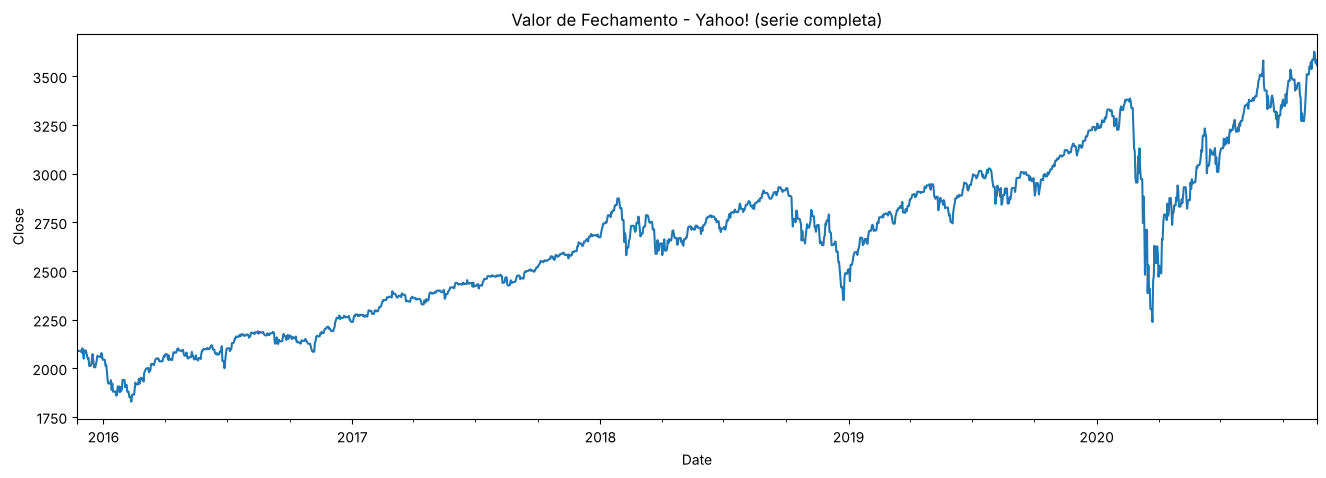

In [ ]:
plt.figure(figsize=(16,5))
serie_original.plot()
plt.title('Valor de Fechamento - Yahoo! (serie completa)')
plt.ylabel('Close')
plt.show()

## 2. Funções de apoio

- `dividir`: separa **treino** e **real** respeitando a ordem do tempo. O argumento `deslocamento` recua o bloco final: `deslocamento=0` é o **teste** (últimos 15 dias) e `deslocamento=15, 30, 45, 60` são os blocos de **validação** (anteriores ao teste).
- `erro_validacao`: MAPE médio de uma combinação de parâmetros nos 4 blocos de validação.
- `metricas`: calcula **MAPE** (usada no notebook da aula), **MAE** e **RMSE** (vistas na aula de regressão).
- `plotar_previsao`: gráfico no mesmo estilo do notebook da aula, com as faixas de ±5% e ±20% ao redor da previsão.

In [ ]:
def dividir(serie, intervalo, deslocamento=0):
    fim = len(serie) - deslocamento
    treino = serie.iloc[:fim - intervalo]
    real = serie.iloc[fim - intervalo:fim]
    return treino, real

def metricas(real, previsto):
    real = np.asarray(real, dtype=float)
    previsto = np.asarray(previsto, dtype=float)
    mape = np.mean(np.abs((previsto - real) / real))
    mae = np.mean(np.abs(previsto - real))
    rmse = np.sqrt(np.mean((previsto - real) ** 2))
    return mape, mae, rmse

ORIGENS_VAL = [15, 30, 45, 60]   # blocos de validacao (todos ANTES do teste)

def erro_validacao(funcao, serie, intervalo, parametros):
    erros = [funcao(serie, intervalo, parametros, deslocamento=d)[0] for d in ORIGENS_VAL]
    return float(np.mean(erros))

def plotar_previsao(serie, previsto, nome, erro):
    x = previsto.index
    y = previsto.values
    plt.figure(figsize=(16,8))
    serie.iloc[len(serie)-2*intervalo:].plot(label='Serie real')
    previsto.plot(label=nome)
    plt.fill_between(x, y*0.95, y+(y*0.05), color='g', alpha=.1)
    plt.fill_between(x, y*0.8, y+(y*0.2), color='r', alpha=.1)
    plt.legend()
    plt.title('MAPE Encontrado na Previsão ('+nome+'): '+str(round(erro*100, 2))+'%')
    plt.show()

## 3. Modelos de referência: ETS (da aula) e baseline ingênuo

A função `previsao_ets` é a do notebook da aula, apenas com o argumento `deslocamento` para podermos validar antes de testar. O **baseline ingênuo** (*naive*) simplesmente repete o último valor observado para os próximos 15 dias.

In [ ]:
def previsao_ets(serie, intervalo, parametros, deslocamento=0):
    error, trend, seasonal, initialization, seasonal_periods = parametros
    treino, real = dividir(serie, intervalo, deslocamento)

    model = ETSModel(treino, error=error, trend=trend, seasonal=seasonal,
                     initialization_method=initialization, seasonal_periods=seasonal_periods)
    model_fit = model.fit(disp=0)

    previsto = model_fit.predict(start=len(treino), end=len(treino)+intervalo-1)
    previsto.index = real.index
    erro = metricas(real, previsto)[0]
    return erro, previsto, model_fit

def previsao_naive(serie, intervalo, parametros=None, deslocamento=0):
    treino, real = dividir(serie, intervalo, deslocamento)
    previsto = Series([treino.iloc[-1]] * intervalo, index=real.index)
    return metricas(real, previsto)[0], previsto, None

In [ ]:
# Busca de parametros do ETS (mesma grade da aula) escolhendo pela VALIDACAO (media de 4 blocos)
v_erro = ['add', 'mul']
v_trend = ['add', 'mul']
v_seasonal = ['add', 'mul']
v_init = ['estimated', 'heuristic']
v_period = [18]

res_ets = []
for erro in v_erro:
    for trend in v_trend:
        for seasonal in v_seasonal:
            for init in v_init:
                for period in v_period:
                    parametros = [erro, trend, seasonal, init, period]
                    try:
                        vl = erro_validacao(previsao_ets, serie_original, intervalo, parametros)
                    except Exception:
                        continue
                    res_ets.append((parametros, vl))

res_ets = sorted(res_ets, key=lambda t: t[1])
melhor_ets = res_ets[0][0]
print('Melhores parametros ETS (validacao):', melhor_ets, '| MAPE val: %.2f%%' % (res_ets[0][1]*100))

erro_ets, prev_ets, fit_ets = previsao_ets(serie_original, intervalo, melhor_ets)
erro_naive, prev_naive, _ = previsao_naive(serie_original, intervalo)
print('MAPE no TESTE -> ETS: %.2f%% | Naive: %.2f%%' % (erro_ets*100, erro_naive*100))

Melhores parametros ETS (validacao): ['mul', 'add', 'add', 'estimated', 18] | MAPE val: 2.34%


MAPE no TESTE -> ETS: 1.55% | Naive: 1.46%


## 4. Modelo estatístico: ARIMA

### 4.1 Estacionariedade e diferenciação
O ARIMA exige uma série estacionária. Usamos o teste **ADF** (Augmented Dickey-Fuller): se o p-valor for **< 0,05**, rejeitamos a hipótese de que a série tem raiz unitária (ou seja, ela é estacionária).

Serie original (d=0)         ADF =   -0.870 | p-valor = 0.7976 | NAO estacionaria
1a diferenca (d=1)           ADF =   -8.522 | p-valor = 0.0000 | estacionaria
2a diferenca (d=2)           ADF =  -15.347 | p-valor = 0.0000 | estacionaria


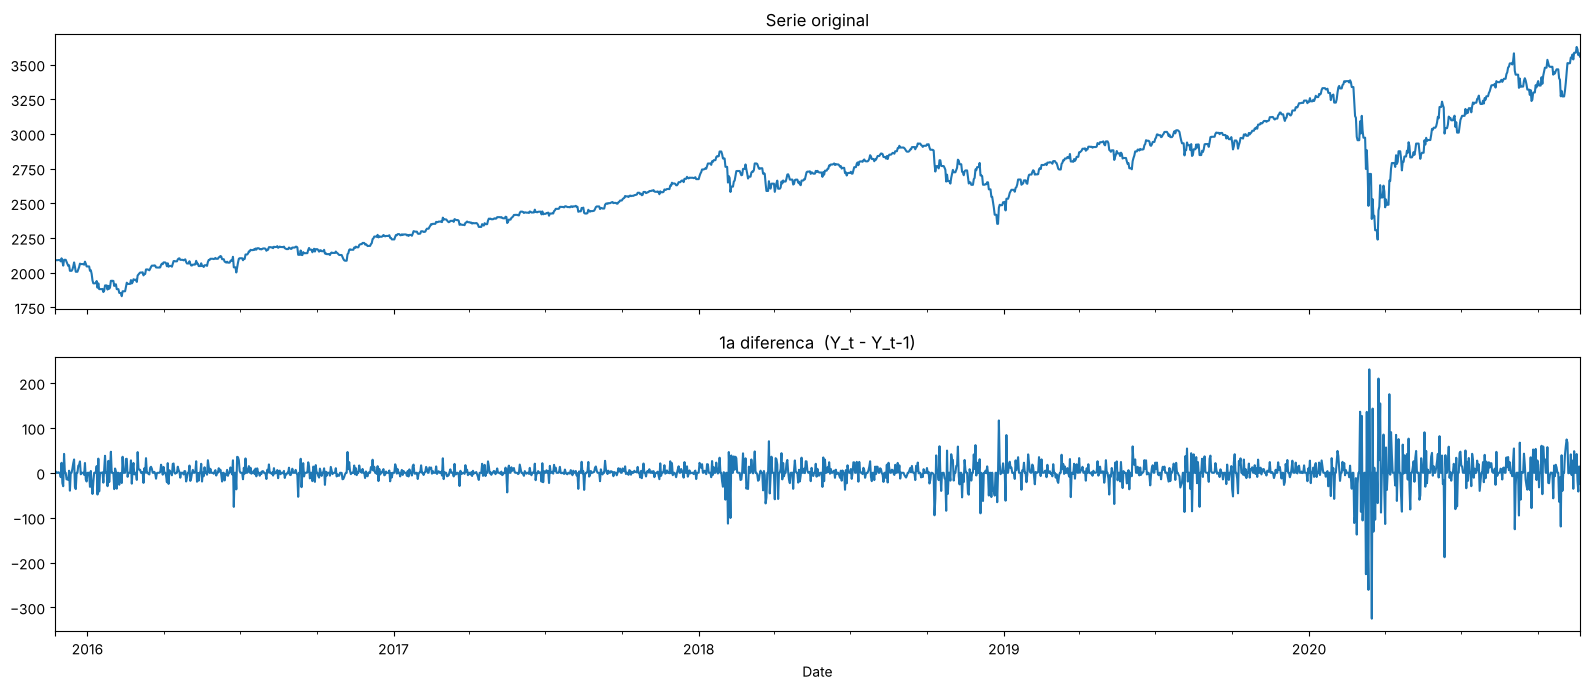

In [ ]:
def teste_adf(s, nome):
    stat, pvalor = adfuller(s.dropna())[:2]
    print('%-28s ADF = %8.3f | p-valor = %.4f | %s' % (nome, stat, pvalor,
          'estacionaria' if pvalor < 0.05 else 'NAO estacionaria'))

teste_adf(serie_original, 'Serie original (d=0)')
teste_adf(serie_original.diff(), '1a diferenca (d=1)')
teste_adf(serie_original.diff().diff(), '2a diferenca (d=2)')

fig, ax = plt.subplots(2, 1, figsize=(16,7), sharex=True)
serie_original.plot(ax=ax[0], title='Serie original')
serie_original.diff().plot(ax=ax[1], title='1a diferenca  (Y_t - Y_t-1)')
plt.tight_layout()
plt.show()

### 4.2 ACF e PACF


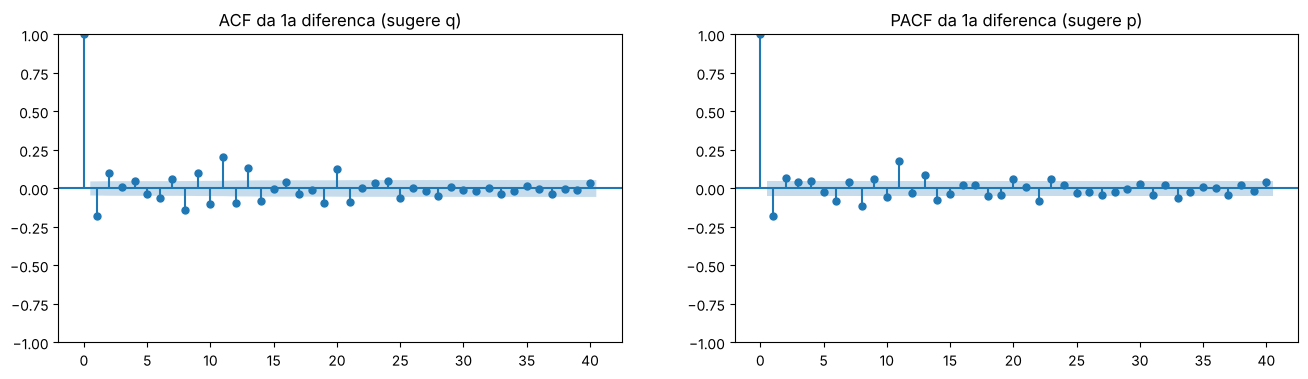

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(16,4))
plot_acf(serie_original.diff().dropna(), lags=40, ax=ax[0], title='ACF da 1a diferenca (sugere q)')
plot_pacf(serie_original.diff().dropna(), lags=40, ax=ax[1], title='PACF da 1a diferenca (sugere p)')
plt.show()

### 4.3 Função de previsão e busca de parâmetros


In [ ]:
def previsao_arima(serie, intervalo, parametros, deslocamento=0):
    p, d, q = parametros
    treino, real = dividir(serie, intervalo, deslocamento)

    model = sm.tsa.ARIMA(treino, order=(p, d, q))
    model_fit = model.fit()

    previsto = model_fit.forecast(steps=intervalo)
    previsto.index = real.index
    erro = metricas(real, previsto)[0]
    return erro, previsto, model_fit

In [ ]:
v_p = [0, 1, 2, 3, 5]
v_d = [0, 1, 2]
v_q = [0, 1, 2]

linhas = []
for p in v_p:
    for d in v_d:
        for q in v_q:
            try:
                vl = erro_validacao(previsao_arima, serie_original, intervalo, (p, d, q))
                linhas.append({'p': p, 'd': d, 'q': q, 'MAPE_validacao_%': vl*100})
            except Exception as e:
                pass

grade_arima = pd.DataFrame(linhas).sort_values('MAPE_validacao_%').reset_index(drop=True)
print('Combinacoes avaliadas:', len(grade_arima))
grade_arima.head(10)

Combinacoes avaliadas: 45


,p,d,q,MAPE_validacao_%
0,5,2,2,2.199382
1,5,2,1,2.280195
2,3,1,2,2.288694
3,5,1,2,2.290548
4,5,1,0,2.295730
5,2,1,2,2.296079
6,1,1,2,2.306054
7,5,0,2,2.308515
8,5,0,1,2.308889
9,2,2,2,2.310380


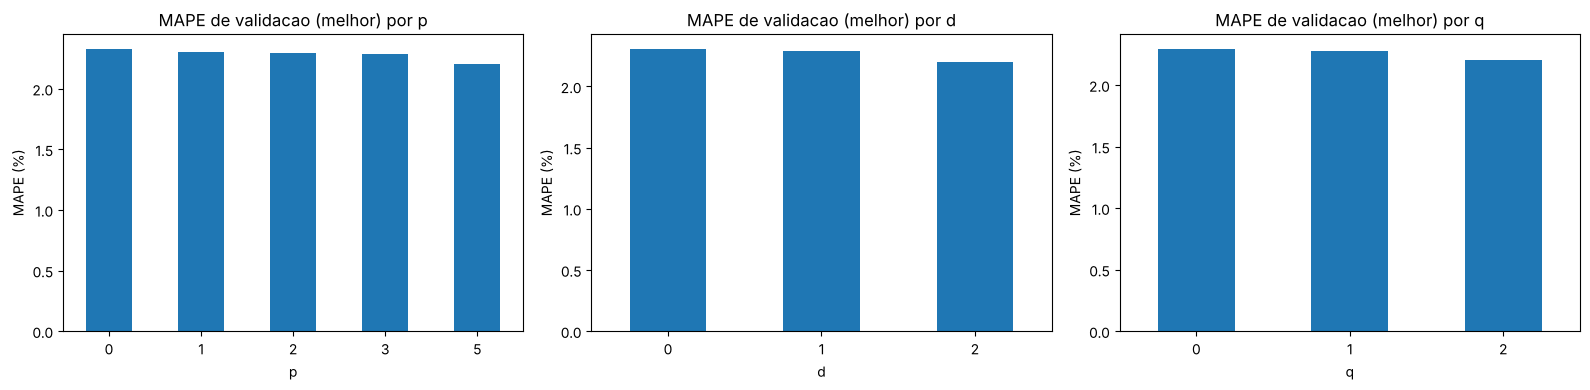

In [ ]:
# Efeito de cada parametro (menor MAPE de validacao ao fixar o valor)
fig, ax = plt.subplots(1, 3, figsize=(16,4))
for a, col in zip(ax, ['p', 'd', 'q']):
    grade_arima.groupby(col)['MAPE_validacao_%'].min().plot(kind='bar', ax=a, rot=0)
    a.set_title('MAPE de validacao (melhor) por ' + col)
    a.set_ylabel('MAPE (%)')
plt.tight_layout()
plt.show()

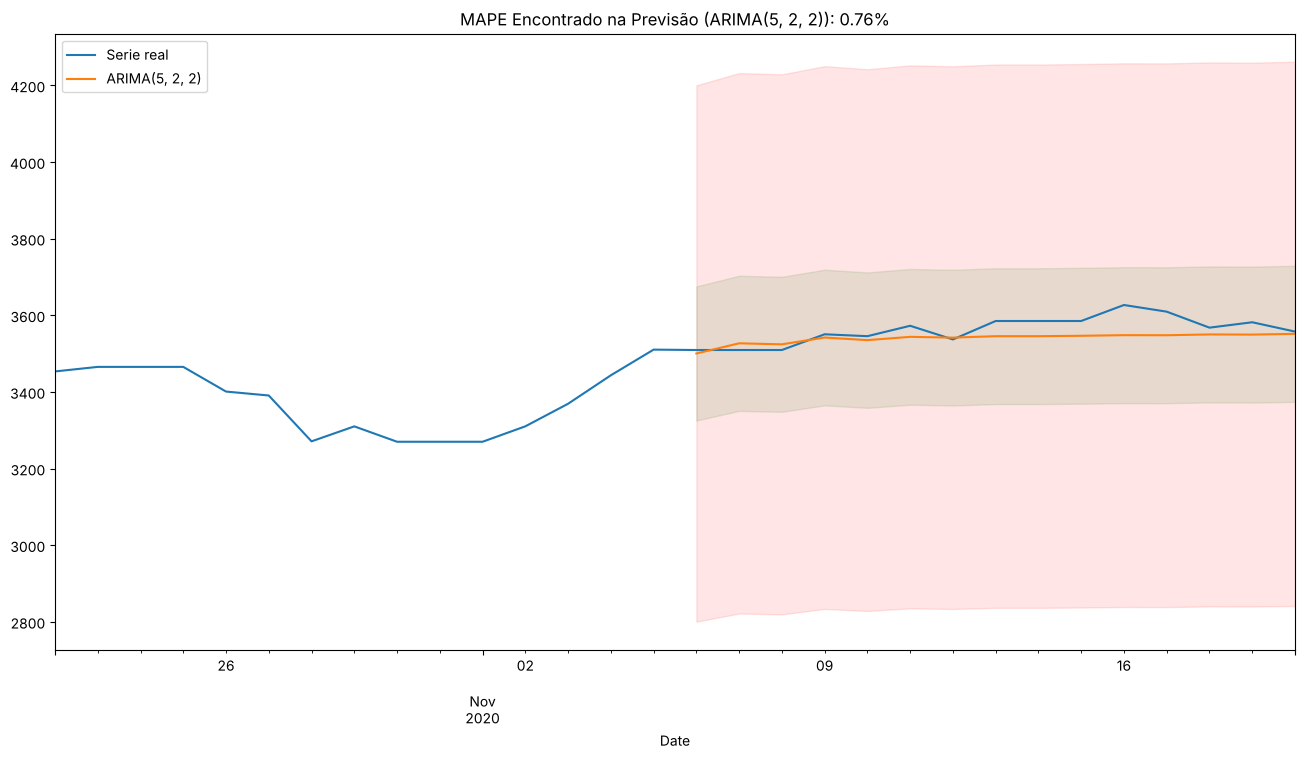

============ Melhores Parametros ============
ARIMA (p, d, q) = (5, 2, 2)
============ Analise de Ruido (residuos) ============
Estatística Jarque-Bera : 11362310.741140744
P-valor : 0.0
Assimetria : -13.852916502027321
Curtose : 390.2675361778934


In [ ]:
melhor_arima = tuple(int(v) for v in grade_arima.loc[0, ['p', 'd', 'q']])
erro_arima, prev_arima, fit_arima = previsao_arima(serie_original, intervalo, melhor_arima)

plotar_previsao(serie_original, prev_arima, 'ARIMA'+str(melhor_arima), erro_arima)

print('============ Melhores Parametros ============')
print('ARIMA (p, d, q) =', melhor_arima)

print('============ Analise de Ruido (residuos) ============')
resid = fit_arima.resid.iloc[1:]
jb = jarque_bera(resid)
print('Estatística Jarque-Bera :', jb[0])
print('P-valor :', jb[1])
print('Assimetria :', jb[2])
print('Curtose :', jb[3])

In [ ]:
print(fit_arima.summary())

                               SARIMAX Results                                
Dep. Variable:                  Close   No. Observations:                 1810
Model:                 ARIMA(5, 2, 2)   Log Likelihood               -8493.138
Date:                Mon, 09 Nov 2026   AIC                          17002.276
Time:                        11:33:23   BIC                          17046.276
Sample:                    11-23-2015   HQIC                         17018.514
                         - 11-05-2020                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -1.0470      0.018    -56.837      0.000      -1.083      -1.011
ar.L2         -0.0772      0.015     -5.217      0.000      -0.106      -0.048
ar.L3          0.1103      0.015      7.138      0.0

## 5. Modelo de detecção de padrões (ML): SVR

O **SVR** (Support Vector Regression) busca uma função que fique dentro de um "tubo" de largura **ε** ao redor dos dados, penalizando só o que sai dele. Para usá-lo em série temporal, transformei a série em um problema supervisionado `f(x) → y`:

- **entrada (x)**: as últimas `janela` observações;
- **saída (y)**: o valor do dia seguinte.

**Cuidado com o nível da série.** O preço sobe ao longo dos anos, e um SVR não extrapola bem valores fora do que viu no treino. Por isso cada janela foi representada em **variação percentual relativa ao último valor da janela**, e o alvo como a variação percentual do dia seguinte. O modelo aprende, portanto, o padrão das *variações*, e o preço previsto é reconstruído a partir do último valor conhecido. A previsão de 15 dias é feita de forma **recursiva** (cada previsão entra na janela da próxima).

**Parâmetros explorados:**
- `janela` (quantos dias de histórico): 5, 10, 20, 30
- `C` (rigidez da penalização): 0,1; 1; 10; 100
- `epsilon` (largura do tubo, em pontos percentuais): 0,01; 0,1; 0,5
- `gamma` (alcance de influência de cada ponto no kernel RBF), como múltiplo do valor padrão `'scale'` do scikit-learn: 0,1x; 1x; 10x

In [ ]:
def montar_janelas(valores, janela):
    X, y = [], []
    for i in range(janela, len(valores)):
        ref = valores[i-1]
        X.append((valores[i-janela:i] / ref - 1) * 100)
        y.append((valores[i] / ref - 1) * 100)
    return np.array(X), np.array(y)

def previsao_svr(serie, intervalo, parametros, deslocamento=0):
    janela, C, epsilon, gmult = parametros
    treino, real = dividir(serie, intervalo, deslocamento)
    valores = treino.values.astype(float)

    X, y = montar_janelas(valores, janela)
    gamma = gmult / (X.shape[1] * X.var())   # gmult x o gamma 'scale' do sklearn
    modelo = SVR(kernel='rbf', C=C, epsilon=epsilon, gamma=gamma)
    modelo.fit(X, y)

    historico = list(valores[-janela:])
    previsoes = []
    for _ in range(intervalo):               # previsao recursiva
        ref = historico[-1]
        x = (np.array(historico[-janela:]) / ref - 1) * 100
        retorno = modelo.predict(x.reshape(1, -1))[0]
        proximo = ref * (1 + retorno / 100)
        previsoes.append(proximo)
        historico.append(proximo)

    previsto = Series(previsoes, index=real.index)
    erro = metricas(real, previsto)[0]
    return erro, previsto, modelo

In [ ]:
v_janela = [5, 10, 20, 30]
v_C = [0.1, 1, 10, 100]
v_eps = [0.01, 0.1, 0.5]
v_gamma = [0.1, 1, 10]

linhas = []
for janela in v_janela:
    for C in v_C:
        for eps in v_eps:
            for g in v_gamma:
                vl = erro_validacao(previsao_svr, serie_original, intervalo, (janela, C, eps, g))
                linhas.append({'janela': janela, 'C': C, 'epsilon': eps, 'gamma_x': g, 'MAPE_validacao_%': vl*100})

grade_svr = pd.DataFrame(linhas).sort_values('MAPE_validacao_%').reset_index(drop=True)
print('Combinacoes avaliadas:', len(grade_svr))
grade_svr.head(10)

Combinacoes avaliadas: 144


,janela,C,epsilon,gamma_x,MAPE_validacao_%
0,20,10.0,0.50,10.0,1.747529
1,20,10.0,0.10,10.0,1.930659
2,20,100.0,0.50,1.0,1.951180
3,20,10.0,0.01,10.0,1.957577
4,20,1.0,0.50,10.0,1.968230
5,20,10.0,0.50,1.0,2.005900
6,30,100.0,0.10,1.0,2.080210
7,30,100.0,0.50,1.0,2.130909
8,20,1.0,0.50,1.0,2.133172
9,20,100.0,0.01,10.0,2.145869


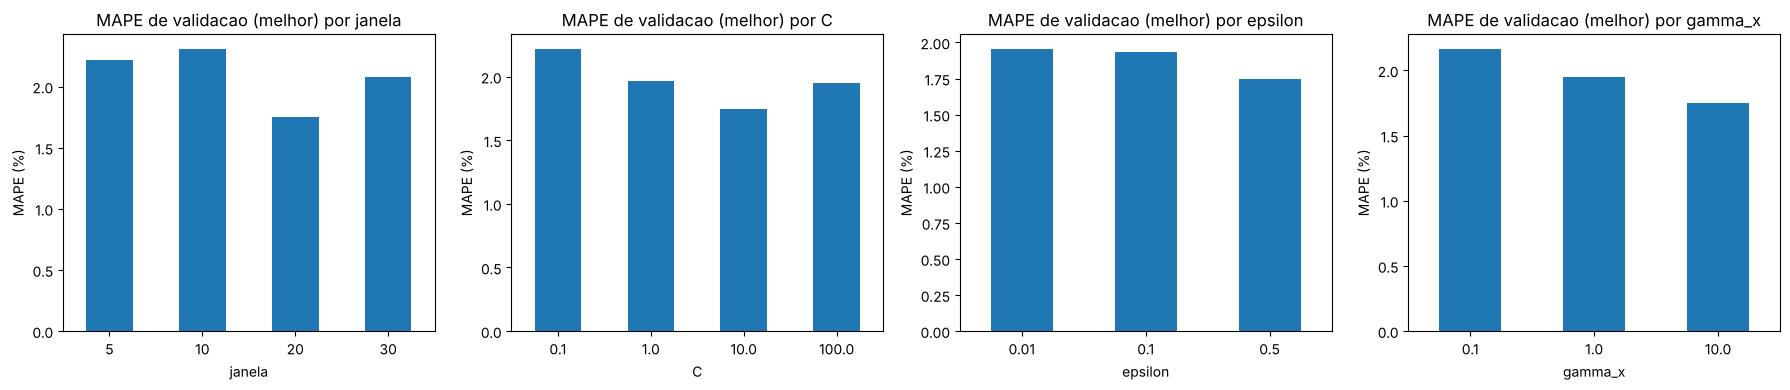

In [ ]:
# Efeito dos hiperparametros (melhor MAPE de validacao ao fixar cada valor)
fig, ax = plt.subplots(1, 4, figsize=(18,4))
for a, col in zip(ax, ['janela', 'C', 'epsilon', 'gamma_x']):
    grade_svr.groupby(col)['MAPE_validacao_%'].min().plot(kind='bar', ax=a, rot=0)
    a.set_title('MAPE de validacao (melhor) por ' + col)
    a.set_ylabel('MAPE (%)')
plt.tight_layout()
plt.show()

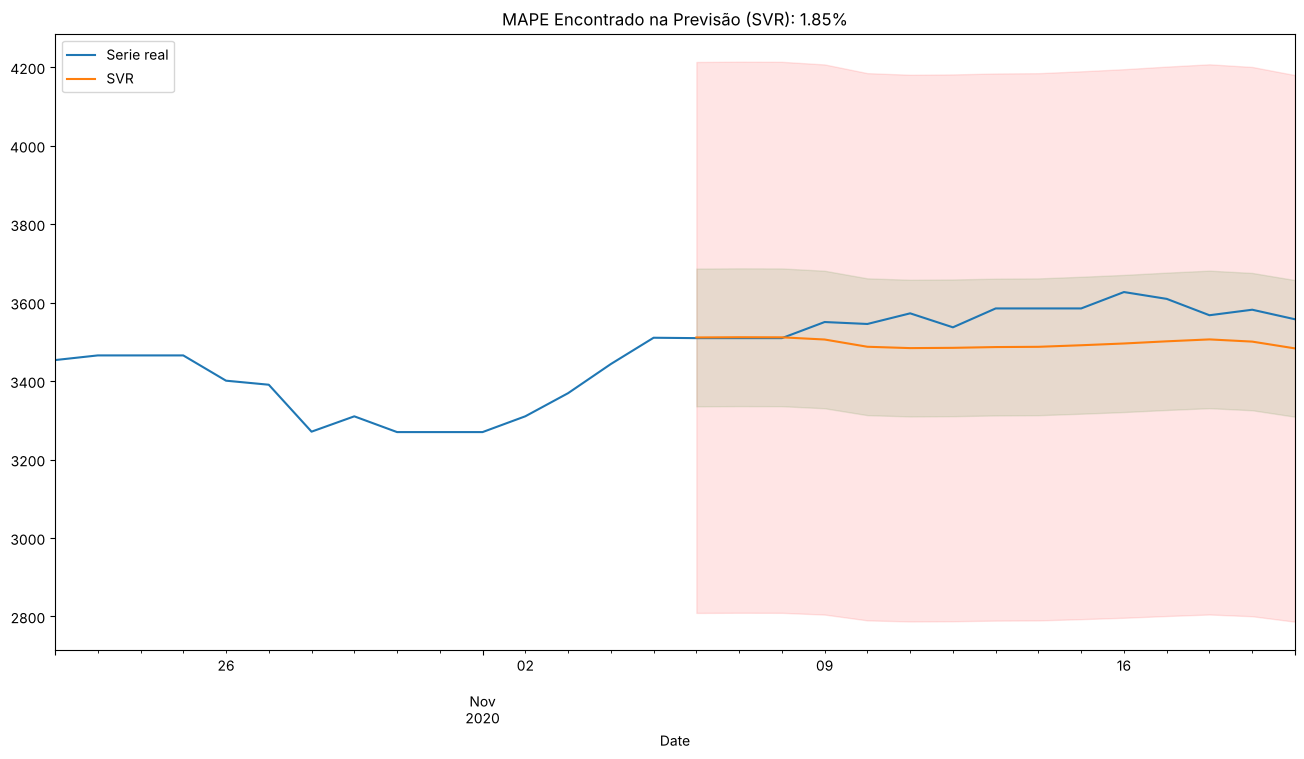

============ Melhores Parametros ============
SVR (janela, C, epsilon, gamma_x) = (20, 10.0, 0.5, 10.0)
Numero de vetores de suporte: 668


In [ ]:
melhor_svr = (int(grade_svr.loc[0,'janela']), float(grade_svr.loc[0,'C']), float(grade_svr.loc[0,'epsilon']), float(grade_svr.loc[0,'gamma_x']))
erro_svr, prev_svr, fit_svr = previsao_svr(serie_original, intervalo, melhor_svr)

plotar_previsao(serie_original, prev_svr, 'SVR', erro_svr)

print('============ Melhores Parametros ============')
print('SVR (janela, C, epsilon, gamma_x) =', melhor_svr)
print('Numero de vetores de suporte:', len(fit_svr.support_))

## 6. Comparação final

### 6.1 Desempenho no teste (últimos 15 dias)

In [ ]:
previsoes = {'Naive (baseline)': prev_naive, 'ETS': prev_ets, 'ARIMA'+str(melhor_arima): prev_arima, 'SVR': prev_svr}
_, real_teste = dividir(serie_original, intervalo)

linhas = []
for nome, prev in previsoes.items():
    mape, mae, rmse = metricas(real_teste, prev)
    linhas.append({'Modelo': nome, 'MAPE (%)': mape*100, 'MAE': mae, 'RMSE': rmse})
tabela = pd.DataFrame(linhas).sort_values('MAPE (%)').reset_index(drop=True)
tabela

,Modelo,MAPE (%),MAE,RMSE
0,"ARIMA(5, 2, 2)",0.758412,27.183777,34.296848
1,Naive (baseline),1.455164,52.161361,62.257224
2,ETS,1.548149,55.452249,64.011837
3,SVR,1.854352,66.418139,76.962929


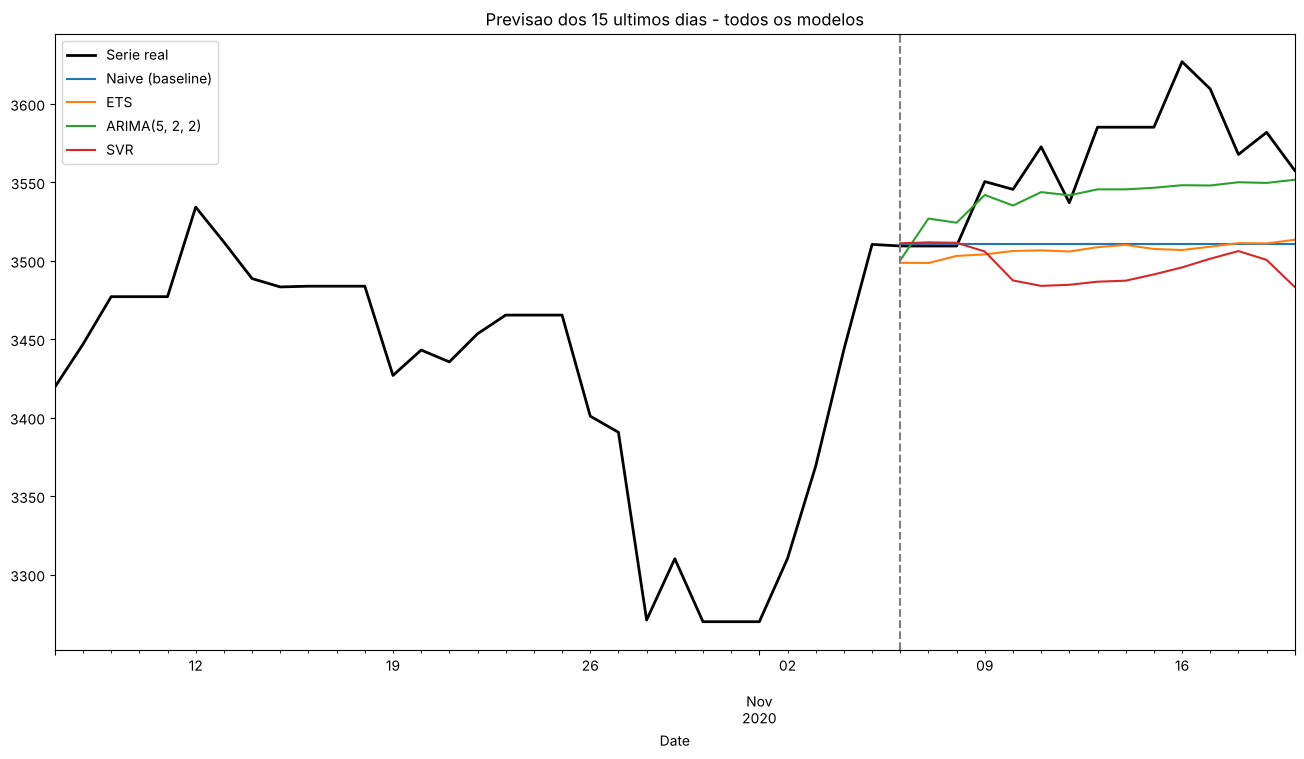

In [ ]:
plt.figure(figsize=(16,8))
serie_original.iloc[serie_size-3*intervalo:].plot(label='Serie real', color='black', linewidth=2)
for nome, prev in previsoes.items():
    prev.plot(label=nome)
plt.axvline(real_teste.index[0], color='gray', linestyle='--')
plt.legend()
plt.title('Previsao dos 15 ultimos dias - todos os modelos')
plt.show()

### 6.2 Verificação em várias janelas (walk-forward)
Quinze dias é um teste muito curto e uma única janela pode favorecer um modelo por sorte. Para conferir, repeti a previsão de 15 dias em **10 origens diferentes** (recuando 15 dias a cada vez), **sempre com os mesmos parâmetros escolhidos** e treinando apenas com o passado de cada origem.

> Atenção: as origens `-15` a `-60` foram usadas na escolha dos parâmetros, então são apenas uma checagem de estabilidade. A linha `origem -0 dias` é o teste de verdade.

,Naive (baseline),ETS,"ARIMA(5, 2, 2)",SVR
origem -0 dias,1.46,1.55,0.76,1.85
origem -15 dias,2.50,2.63,2.51,2.15
origem -30 dias,3.18,2.79,2.68,2.77
origem -45 dias,1.76,1.49,1.68,1.30
origem -60 dias,2.24,2.45,1.93,0.77
origem -75 dias,2.18,2.08,1.91,2.27
origem -90 dias,0.71,0.47,0.41,1.45
origem -105 dias,1.36,1.15,1.19,2.45
origem -120 dias,1.47,1.40,1.33,2.54
origem -135 dias,1.59,1.53,1.59,2.18


,MAPE medio (%),Desvio padrao,Melhor MAPE,Pior MAPE
"ARIMA(5, 2, 2)",1.60,0.71,0.41,2.68
ETS,1.75,0.72,0.47,2.79
Naive (baseline),1.84,0.70,0.71,3.18
SVR,1.97,0.63,0.77,2.77


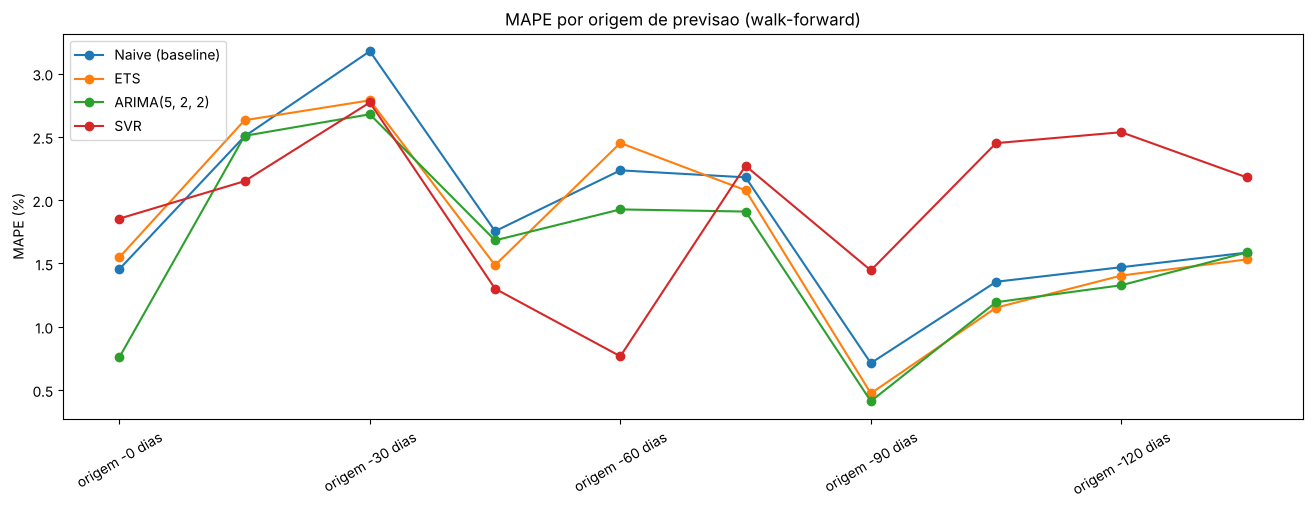

In [ ]:
funcoes = {
    'Naive (baseline)': (previsao_naive, None),
    'ETS': (previsao_ets, melhor_ets),
    'ARIMA'+str(melhor_arima): (previsao_arima, melhor_arima),
    'SVR': (previsao_svr, melhor_svr),
}

origens = [intervalo * k for k in range(0, 10)]   # 0 = teste, 15, 30, ...
walk = {nome: [] for nome in funcoes}
for desloc in origens:
    for nome, (fn, par) in funcoes.items():
        walk[nome].append(fn(serie_original, intervalo, par, deslocamento=desloc)[0] * 100)

walk_df = pd.DataFrame(walk, index=['origem -%d dias' % o for o in origens])
display(walk_df.round(2))

resumo = pd.DataFrame({'MAPE medio (%)': walk_df.mean(), 'Desvio padrao': walk_df.std(), 'Melhor MAPE': walk_df.min(), 'Pior MAPE': walk_df.max()}).sort_values('MAPE medio (%)')
display(resumo.round(2))

walk_df.plot(figsize=(16,5), marker='o')
plt.ylabel('MAPE (%)')
plt.title('MAPE por origem de previsao (walk-forward)')
plt.xticks(rotation=30)
plt.show()

## 7. Conclusões

**Resultado no teste (últimos 15 dias, nunca usados para escolher parâmetros)**

| Modelo | Parâmetros escolhidos | MAPE | MAE | RMSE |
|---|---|---|---|---|
| **ARIMA** (estatístico) | (p,d,q) = (5, 2, 2) | **0,76%** | 27,2 | 34,3 |
| Baseline ingênuo | repetir o último valor | 1,46% | 52,2 | 62,3 |
| ETS (da aula) | (mul, add, add, estimated, 18) | 1,55% | 55,5 | 64,0 |
| **SVR** (ML) | janela=20, C=10, ε=0,5, γ=10x `scale` | 1,85% | 66,4 | 77,0 |

**Na verificação em 10 origens (walk-forward)**, o MAPE médio foi 1,60% (ARIMA), 1,75% (ETS), 1,84% (ingênuo) e 1,97% (SVR).

**Resultado**

1. **O ARIMA foi o melhor modelo**, no teste e na média das origens. A série original não é estacionária (ADF: p = 0,80) e fica estacionária após diferenciar (p ≈ 0), o que justifica o `d` maior que zero. A busca de parâmetros mostrou que `d=1` ou `d=2` e `p` maior (5) funcionam melhor que `d=0`.

